# Composite analysis for NoRad and Rad

## Import packages

In [25]:
import h5py
import numpy as np

from typing import cast
from pathlib import Path

from matplotlib import pyplot as plt

style_path = Path("/home/b11209013/Kuang-python/v0.1.0_Analysis/scientific.mplstyle")

plt.style.use(style_path)

## Configure the experiments

In [26]:
data_path: Path = Path("/work/b11209013/Kuang-python/v0.1.0/two-way/Eastward")
EXPS: list[str] = ["NoRad", "Rad"]
FILES: list[str] = ["2026-10-28-07-25-19-242016551-4092283", "2026-10-28-08-37-05-996147668-3800833"]

# Process both experiments; use EXPS[:1] for NoRad alone.
active_exps: list[str] = EXPS[:]
run_paths: dict[str, Path] = {exp: data_path / exp / run for exp, run in zip(EXPS, FILES)}

# Exclude the first 20 days, as in the reference composite.
skip_days: float = 20.0

## Heating-centered composite method

For each experiment, load the same six Galerkin fields with axes
`(ensemble, time, x, z)` and use its own coordinates. The loading method and
trapezoidal vertical-integration formula are preserved. Select times at or
after `skip_days`, then roll each ensemble/time snapshot so its column-heating
maximum is at the grid point closest to zero. All fields use the same shifts.
As in the reference, `nanargmax` chooses the first maximum when peaks tie.

Average over the selected times and members, ignoring NaNs at each grid point.
Add the two modes before averaging to obtain total `J`, `w`, and `T`.
The helper accumulates one snapshot at a time; each composite has shape `(x, z)`.

In [27]:
def heating_centered_composite(field, shifts, time_indices, second_field=None):
    """Composite (ensemble, time, x, z) data using heating-based x shifts."""
    if field.ndim != 4:
        raise ValueError("Expected field axes (ensemble, time, x, z).")
    if shifts.shape != (field.shape[0], len(time_indices)):
        raise ValueError("Provide one shift for each retained ensemble/time pair.")
    if second_field is not None and second_field.shape != field.shape:
        raise ValueError("The two modal fields must have matching shapes.")
    total = np.zeros(field.shape[2:], dtype=np.result_type(field.dtype, np.float64))
    count = np.zeros(field.shape[2:], dtype=np.int64)
    for ne in range(field.shape[0]):
        for jt, it in enumerate(time_indices):
            snapshot = field[ne, it]
            if second_field is not None:
                snapshot = snapshot + second_field[ne, it]
            centered = np.roll(snapshot, int(shifts[ne, jt]), axis=0)
            valid = ~np.isnan(centered)
            total += np.where(valid, centered, 0)
            count += valid
    composite = np.full(total.shape, np.nan, dtype=total.dtype)
    np.divide(total, count, out=composite, where=count > 0)
    return composite

## Load and composite each run

The loop processes one experiment at a time so the full NoRad and Rad fields
need not remain in memory together. `composite_results[exp]` keeps the run's
coordinates and centering diagnostics; `composites[exp]` contains its nine
composite fields.

In [28]:
def composite_experiment(experiment, run_path, skip_days):
    # Load Galerkin State
    with h5py.File(run_path / "GalerkinState.h5", "r") as f:
        x: np.ndarray = cast(h5py.Dataset, f["x"])[:]
        z: np.ndarray = cast(h5py.Dataset, f["z"])[:]
        t: np.ndarray = cast(h5py.Dataset, f["time"])[:]

        data: dict[str, np.ndarray] = {
            key: cast(h5py.Dataset, f[key])[...]
            for key in ["w1", "w2", "T1", "T2", "J1", "J2"]
        } # shape: (ensemble, time, zonal, level)

    nens, nt, nx, nz = data["w1"].shape

    # combining J1 and J2 to form Qc
    Qc: np.ndarray = data["J1"] + data["J2"]

    # vertically integrate Qc
    Qc_column: np.ndarray = np.trapz(Qc, z, axis=-1) / np.trapz(np.ones_like(z), z, axis=-1)

    composite_time_indices = np.flatnonzero(t >= skip_days)
    if nens == 0 or composite_time_indices.size == 0:
        raise ValueError("The composite requires at least one member and one retained time.")
    print(f"{experiment}: compositing {nens} members and {composite_time_indices.size} times "
          f"from {t[composite_time_indices[0]]:g} to {t[composite_time_indices[-1]]:g} days.")

    # Keep the existing center at x closest to zero (NX // 2 on this grid).
    x_center_idx: np.intp = np.argmin(np.abs(x))

    # Each retained (ensemble, time) pair gets its own shift.
    Qc_column_selected = Qc_column[:, composite_time_indices, :]
    if np.any(np.all(np.isnan(Qc_column_selected), axis=-1)):
        raise ValueError("Cannot locate a heating maximum in an all-NaN column profile.")
    Qc_column_max = np.nanargmax(Qc_column_selected, axis=-1)
    shifts: np.ndarray = x_center_idx - Qc_column_max  # (ensemble, retained time)

    # Preserve Qc_column so this cell can be rerun without shifting the input again.
    Qc_column_rolled = np.empty_like(Qc_column_selected)
    for ne in range(nens):
        for jt in range(composite_time_indices.size):
            Qc_column_rolled[ne, jt] = np.roll(
                Qc_column_selected[ne, jt], int(shifts[ne, jt]), axis=0,
            )

    Qc_column_composite = np.nanmean(Qc_column_rolled, axis=(0, 1))  # (x,)

    composite: dict[str, np.ndarray] = {
        key: heating_centered_composite(values, shifts, composite_time_indices)
        for key, values in data.items()
    }
    composite["J"] = heating_centered_composite(Qc, shifts, composite_time_indices)
    for key in ("w", "T"):
        composite[key] = heating_centered_composite(
            data[f"{key}1"], shifts, composite_time_indices,
            second_field=data[f"{key}2"],
        )

    # Coordinates relative to the heating center, for plots or subsequent analysis.
    x_relative = x - x[x_center_idx]
    print(f"{experiment} composite field shapes:", {key: value.shape for key, value in composite.items()})

    return {
        "fields": composite,
        "x": x,
        "z": z,
        "time": t[composite_time_indices],
        "x_relative": x_relative,
        "nens": nens,
        "shifts": shifts,
        "column_composite": Qc_column_composite,
        "column_first_time": Qc_column_rolled[:, 0, :].copy(),
    }

In [29]:
# Check both inputs before starting the expensive loading and integration.
for exp in active_exps:
    source_path = run_paths[exp] / "GalerkinState.h5"
    if not source_path.is_file():
        raise FileNotFoundError(f"{exp}: missing {source_path}")
    with h5py.File(source_path, "r") as f:
        if not f.attrs.get("complete", False):
            raise ValueError(f"{exp}: Galerkin reconstruction is incomplete.")

composite_results = {}
for exp in active_exps:
    composite_results[exp] = composite_experiment(exp, run_paths[exp], skip_days)

composites = {exp: result["fields"] for exp, result in composite_results.items()}

NoRad: compositing 90 members and 20 times from 20.375 to 39.375 days.
NoRad composite field shapes: {'w1': (401, 71), 'w2': (401, 71), 'T1': (401, 71), 'T2': (401, 71), 'J1': (401, 71), 'J2': (401, 71), 'J': (401, 71), 'w': (401, 71), 'T': (401, 71)}
Rad: compositing 90 members and 20 times from 20.375 to 39.375 days.
Rad composite field shapes: {'w1': (401, 71), 'w2': (401, 71), 'T1': (401, 71), 'T2': (401, 71), 'J1': (401, 71), 'J2': (401, 71), 'J': (401, 71), 'w': (401, 71), 'T': (401, 71)}


## Inspect the centered column-heating profiles

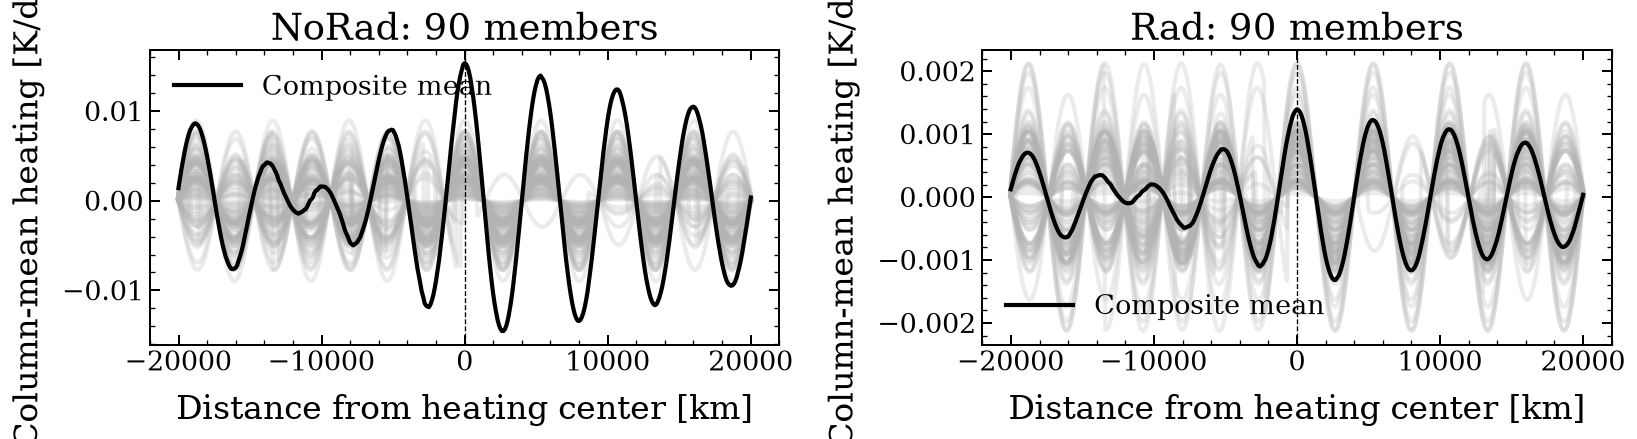

In [30]:
fig, axes = plt.subplots(1, len(active_exps), figsize=(7 * len(active_exps), 4), squeeze=False)
for ax, exp in zip(axes[0], active_exps):
    result = composite_results[exp]
    distance_km = result["x_relative"] / 1000.0
    # Every member at the first retained time, plus the full composite mean.
    ax.plot(distance_km, result["column_first_time"].T, color="0.7", alpha=0.25)
    ax.plot(distance_km, result["column_composite"], color="k", label="Composite mean")
    ax.axvline(0, color="k", linestyle="--", linewidth=0.8)
    ax.set(xlabel="Distance from heating center [km]", ylabel="Column-mean heating [K/day]",
           title=f"{exp}: {result['nens']} members")
    ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

## Compare the composite fields

Each row is an experiment; columns show heating with vertical velocity and
temperature contours. Use each run's own grid and display relative longitudes
within ±50°. By default each row has its own labeled color scale and contour
levels so the weaker signal remains visible. Set `shared_scale = True` to use
common levels for comparing absolute amplitudes. Transpose `(x, z)` only for plotting.


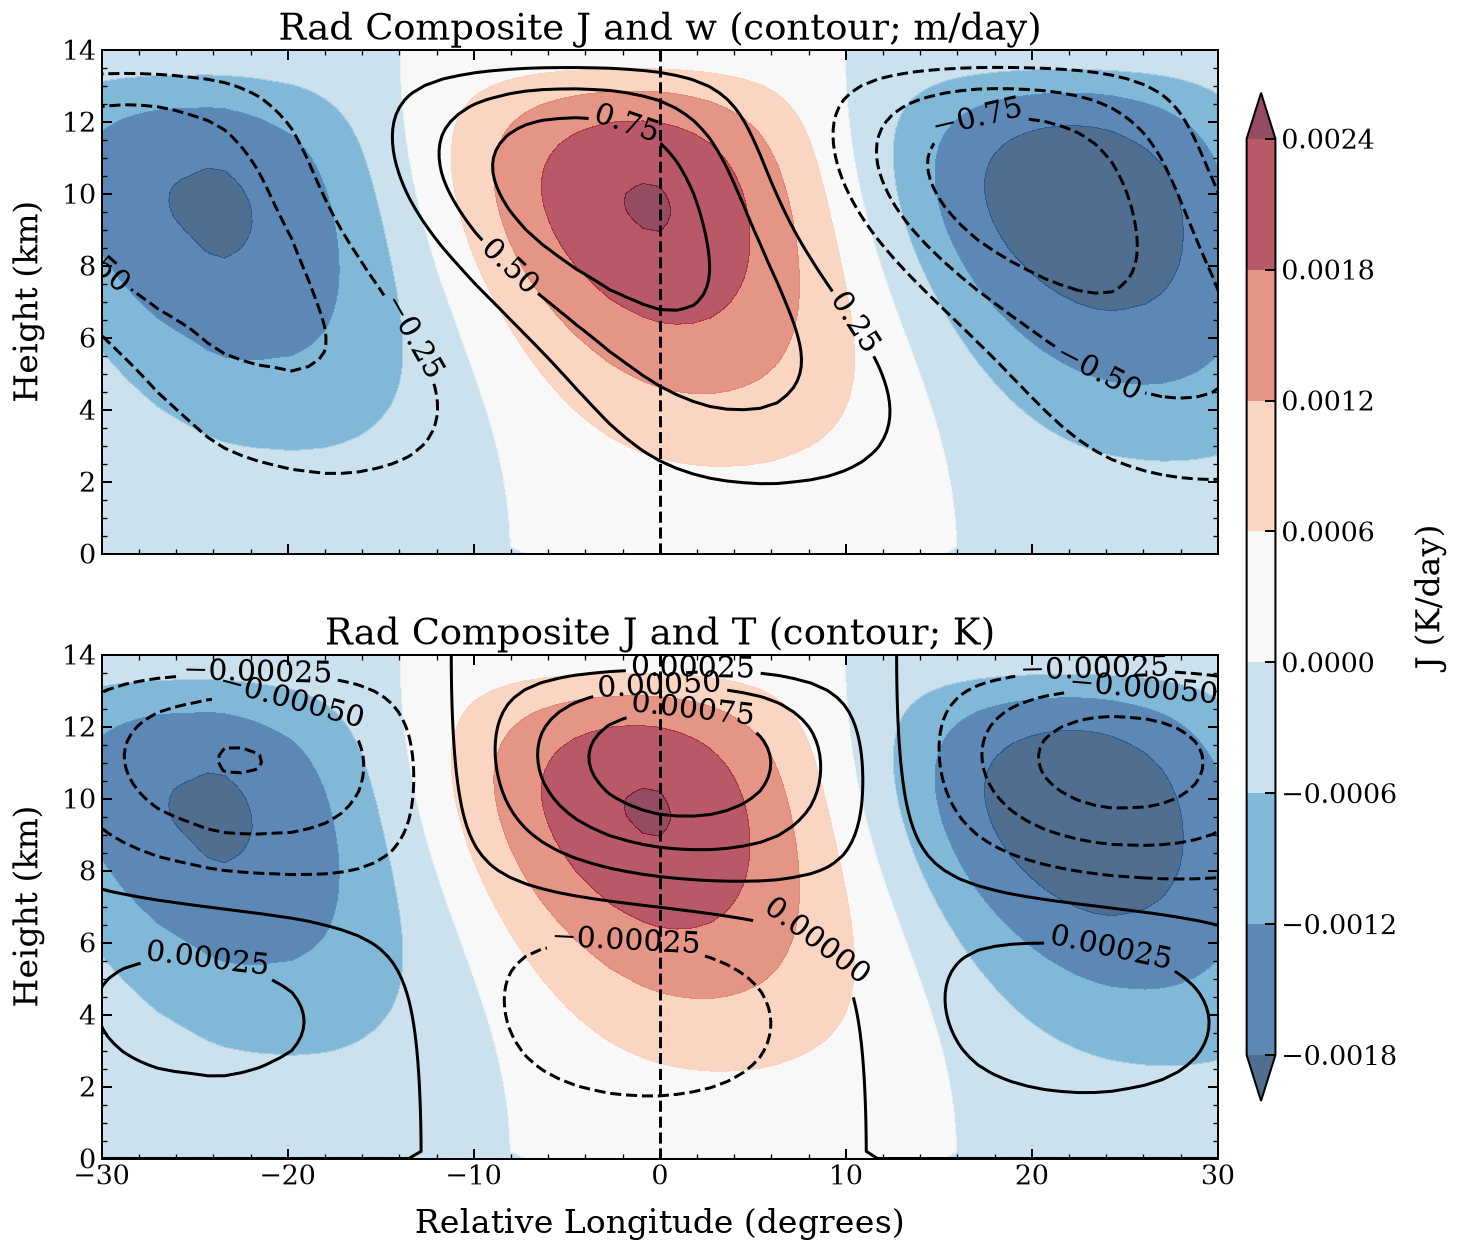

In [40]:
metres_per_degree = 2 * np.pi * 6.371e6 / 360.0
shared_scale = False  # True compares absolute amplitudes on common levels.
plot_coordinates = {}

# defining relative longitude
longitude: np.ndarray = composite_results[active_exps[0]]["x_relative"] / metres_per_degree
z        : np.ndarray = composite_results[active_exps[0]]["z"] / 1000.0

exp: str = "Rad"

# find the maximum of temperature and vertical motion
w_max = np.round(np.max(np.abs(composite_results[exp]["fields"]["w"])), decimals=0)
T_max = np.round(np.max(np.abs(composite_results[exp]["fields"]["T"])), decimals=4)

# plot figure
fig, axes = plt.subplots(
    2, 1, figsize = (12, 12),
    sharex=True
)

ax1, ax2 = axes.flatten()

norad_J_ctf = ax1.contourf(
    longitude, z, composite_results[exp]["fields"]["J"].T,
    cmap="RdBu_r", extend="both", alpha=0.7
)
norad_w_ctf = ax1.contour(
    longitude, z, composite_results[exp]["fields"]["w"].T,
    colors="k", linewidths=1.8,
    levels=[i for i in np.arange(-w_max, w_max, w_max/4) if np.abs(i) >= 0.1]
)
ax1.set(
    # xlabel="Relative Longitude (degrees)",
    ylabel="Height (km)",
    xlim=(-30, 30),
    ylim=(0, np.max(z)),
    title=f"{exp} Composite J and w (contour; m/day)"
)
ax1.axvline(0.0, color="k", linewidth=1.8, linestyle="--")
plt.clabel(norad_w_ctf, fontsize=18)

norad_J_ctf = ax2.contourf(
    longitude, z, composite_results[exp]["fields"]["J"].T,
    cmap="RdBu_r", extend="both", alpha=0.7
)
norad_T_ctf = ax2.contour(
    longitude, z, composite_results[exp]["fields"]["T"].T,
    colors="k", linewidths=1.8,
    levels=[i for i in np.arange(-T_max, T_max, T_max/4)]
)
ax2.axvline(0.0, color="k", linewidth=1.8, linestyle="--")
ax2.set(
    xlabel="Relative Longitude (degrees)",
    ylabel="Height (km)",
    xlim=(-30, 30),
    ylim=(0, np.max(z)),
    title=f"{exp} Composite J and T (contour; K)"
)
plt.clabel(norad_T_ctf, fontsize=18)


cax = fig.add_axes((0.92, 0.15, 0.02, 0.7))  # (left, bottom, width, height)
fig.colorbar(norad_J_ctf, cax=cax, label="J (K/day)")

plt.savefig(f"/home/b11209013/Kuang-python/v0.1.0_Analysis/Figure/{exp}_composite_J_w_T.png")
plt.show()